# Notebook 05 - Synthetic Signal Analysis

This notebook analyzes invented values from anonymous signal channels. Results are illustrative and are not sourced from an organization or operating asset.

## Analysis step 2

Import modeling and evaluation tools, define project paths, and set the chronological validation and modeling options.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             confusion_matrix, precision_recall_curve)

warnings.filterwarnings('ignore', category=UserWarning)
sns.set_theme(style='whitegrid')

HERE = Path.cwd().resolve()
ROOT = None
PROCESSED = None

for candidate in [HERE, *HERE.parents]:
    processed_candidate = candidate / 'data' / 'processed'
    if (processed_candidate / 'features_labels.csv').is_file():
        ROOT = candidate
        PROCESSED = processed_candidate
        break

# If the files are uploaded directly to Colab, use their current folder.
if ROOT is None:
    for candidate in [HERE, *HERE.parents]:
        if (candidate / 'features_labels.csv').is_file():
            ROOT = candidate
            PROCESSED = candidate
            break

if ROOT is None:
    raise FileNotFoundError('Could not find features_labels.csv (and label_config.json).')

FIG_DIR = ROOT / 'reports' / 'figures'
OUT_DIR = ROOT / 'reports' / 'tables'
MODEL_DIR = ROOT / 'models'
for d in (FIG_DIR, OUT_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- settings -------------------------------------------------------------
RANDOM_STATE = 42
BLOCK_DAYS = 14        # length of each held-out block
GAP_DAYS = 7           # days removed from training on both sides of a block
MIN_POS_TRAIN = 3      # a fold is skipped if its training part has fewer positives
THRESHOLD = 0.5        # probability threshold for an alarm day
SUSTAIN_K = 3          # an alarm needs K usable days in a row above the threshold
LR_C = 0.1             # fixed on purpose (see section 4)
TREE_DEPTH = 3
RUN_CATBOOST = False   # set True only if catboost is installed

print('Project path:', ROOT)
print('PROCESSED:', PROCESSED)

Project path: D:\ML_NTI\Predictive Maintanance\predictive-maintenance
PROCESSED: D:\ML_NTI\Predictive Maintanance\predictive-maintenance\data\processed


In [2]:
table = pd.read_csv(PROCESSED / 'features_labels.csv', index_col=0, parse_dates=True)
with open(PROCESSED / 'label_config.json') as f:
    cfg = json.load(f)

FAILURE_DATE = pd.Timestamp(cfg['failure_date_used'])
FAILURE_PROVISIONAL = cfg.get('failure_date_provisional', True)
HORIZONS = cfg['horizons']
MAIN_H = cfg['main_horizon']

# Feature list from notebook 04 + the three baseline-distance scores.
feat_path = PROCESSED / 'feature_list.csv'
if feat_path.is_file():
    FEATURES = pd.read_csv(feat_path)['feature'].tolist()
else:
    FEATURES = [c for c in table.columns if '__' in c]
SCORES = [c for c in ['health_abs7', 'health_max7', 'mahal7'] if c in table.columns]
FEATURES = [c for c in FEATURES if c in table.columns] + [c for c in SCORES if c not in FEATURES]

# Only rows that notebook 04 marked usable and that have a valid label.
df = table[table['usable'].astype(bool) & table['label_valid'].astype(bool)].copy()
y_main = df[f'label_h{MAIN_H}'].astype(int).to_numpy()

print('failure date used:', FAILURE_DATE.date(), '(provisional)' if FAILURE_PROVISIONAL else '(confirmed)')
print('horizons:', HORIZONS, '| main horizon:', MAIN_H)
print('features:', len(FEATURES))
print('usable labelled rows:', len(df), '| positives at main horizon:', int(y_main.sum()))
print('feature NaNs in usable rows:', int(df[FEATURES].isna().sum().sum()))

failure date used: 2033-12-31 (provisional)
horizons: [14, 30, 60] | main horizon: 30
features: 87
usable labelled rows: 657 | positives at main horizon: 31
feature NaNs in usable rows: 0


## Analysis step 3

Load the feature and label table plus the label configuration. The configured failure date and horizon determine which target the main model evaluation predicts.

In [3]:
rows = []
for split, g in df.groupby('split'):
    r = {'split': split, 'rows': len(g), 'first_day': g.index.min().date(), 'last_day': g.index.max().date()}
    for h in HORIZONS:
        r[f'positives_h{h}'] = int(g[f'label_h{h}'].sum())
    rows.append(r)
split_table = pd.DataFrame(rows).set_index('split').loc[['train', 'validation', 'test']]
display(split_table)

pos_days = df.index[df[f'label_h{MAIN_H}'] == 1]
print(f'Positive days at h={MAIN_H}: {pos_days.min().date()} to {pos_days.max().date()} ({len(pos_days)} rows)')
train_val_pos = int(split_table.loc[['train', 'validation'], f'positives_h{MAIN_H}'].sum())
print(f'Positives in train + validation: {train_val_pos}')
if train_val_pos == 0:
    print('-> A supervised model trained on train / validation sees only one class and cannot learn.')
    print('   Section 2 uses a purged blocked cross-validation as a proof of concept instead.')

,rows,first_day,last_day,positives_h14,positives_h30,positives_h60
split,,,,,,
train,353,2032-01-15,2033-01-01,0,0,0
validation,150,2033-01-02,2033-06-18,0,0,0
test,154,2033-07-11,2033-12-31,15,31,61


Positive days at h=30: 2033-12-01 to 2033-12-31 (31 rows)
Positives in train + validation: 0
-> A supervised model trained on train / validation sees only one class and cannot learn.
   Section 2 uses a purged blocked cross-validation as a proof of concept instead.


## Analysis step 4

Summarize row counts and positive labels by chronological split and forecast horizon. This reveals whether each split contains enough examples for meaningful evaluation.

In [4]:
def make_lr(C=LR_C):
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', RobustScaler()),
        ('model', LogisticRegression(C=C, class_weight='balanced', max_iter=5000,
                                     random_state=RANDOM_STATE)),
    ])

def make_tree(depth=TREE_DEPTH):
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('model', DecisionTreeClassifier(max_depth=depth, min_samples_leaf=5,
                                         class_weight='balanced', random_state=RANDOM_STATE)),
    ])

def make_catboost():
    from catboost import CatBoostClassifier
    return CatBoostClassifier(depth=3, iterations=200, learning_rate=0.05,
                              auto_class_weights='Balanced', random_seed=RANDOM_STATE,
                              verbose=0, allow_writing_files=False)

def block_ids(index, block_days):
    return ((index - index.min()).days // block_days).to_numpy()

def purged_oof(make_model, X, y, index, block_days=BLOCK_DAYS, gap_days=GAP_DAYS,
               min_pos_train=MIN_POS_TRAIN, verbose=False):
    """Walk-forward out-of-fold probability for every row.

    For each validation block the model is trained ONLY on observations that lie
    strictly before the block, leaving a purge gap of `gap_days` before it. No
    future observation (including anything after the failure window) is ever used.
    A block is skipped, leaving NaN, when its training window has fewer than
    `min_pos_train` examples of either class.
    """
    blocks = block_ids(index, block_days)
    proba = pd.Series(np.nan, index=index)
    gap = pd.Timedelta(days=gap_days)
    n_trained = 0
    n_skipped = 0
    for b in np.unique(blocks):
        test = blocks == b
        t0 = index[test].min()
        train = np.asarray(index < (t0 - gap))
        # leak-proof checks: training must strictly precede the purged block
        assert not (train & test).any(), 'a row is both training and validation'
        if train.any():
            assert index[train].max() < (t0 - gap), \
                'training data leaks into the purged validation window'
        ytr = y[train]
        if ytr.sum() < min_pos_train or (ytr == 0).sum() < min_pos_train:
            n_skipped += 1
            continue
        model = make_model()
        model.fit(X[train], ytr)
        proba.iloc[np.where(test)[0]] = model.predict_proba(X[test])[:, 1]
        n_trained += 1
    if verbose:
        print(f'walk-forward folds: {n_trained} trained, {n_skipped} skipped '
              f'(training window had fewer than {min_pos_train} examples of a class)')
    return proba

X_all = df[FEATURES]
print('blocks:', len(np.unique(block_ids(df.index, BLOCK_DAYS))), 'of', BLOCK_DAYS, 'days')

blocks: 51 of 14 days


### Analysis step 5

Define the logistic regression and decision tree pipelines, including imputation and scaling where needed. Keeping preprocessing inside each pipeline ensures it is fitted only on training folds.

In [5]:
def summarize(proba, y, name, threshold=None):
    ok = proba.notna().to_numpy()
    yy, pp = y[ok], proba[ok].to_numpy()
    out = {'model': name, 'scored_rows': int(ok.sum()), 'scored_pos': int(yy.sum()),
           'total_pos': int(y.sum()), 'prevalence': float(yy.mean()) if len(yy) else np.nan}
    if len(np.unique(yy)) < 2:
        out.update(PR_AUC=np.nan, ROC_AUC=np.nan)
        return out
    out['PR_AUC'] = average_precision_score(yy, pp)
    out['ROC_AUC'] = roc_auc_score(yy, pp)
    if threshold is not None:
        pred = (pp >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(yy, pred, labels=[0, 1]).ravel()
        prec = tp / (tp + fp) if (tp + fp) else 0.0
        rec = tp / (tp + fn) if (tp + fn) else 0.0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
        out.update(precision=prec, recall=rec, F1=f1, TN=tn, FP=fp, FN=fn, TP=tp)
    return out

def sustained_alarm(proba, seg, threshold=THRESHOLD, k=SUSTAIN_K):
    flag = (proba >= threshold).fillna(False).astype(int)
    roll = flag.groupby(seg.to_numpy()).transform(lambda s: s.rolling(k).min())
    return roll.fillna(0).astype(bool)

def episode_starts(alarm):
    a = alarm.astype(int).to_numpy()
    prev = np.r_[0, a[:-1]]
    return alarm.index[(a == 1) & (prev == 0)]

def event_timing(proba, y, seg, name, horizon=MAIN_H):
    alarm = sustained_alarm(proba, seg)
    starts = episode_starts(alarm)
    h_start = FAILURE_DATE - pd.Timedelta(days=horizon)
    ok = proba.notna().to_numpy()
    healthy_days = int(((y == 0) & ok).sum())
    false_days = int((alarm.to_numpy() & (y == 0)).sum())
    first = alarm.index[alarm.to_numpy()].min() if alarm.any() else pd.NaT
    return {
        'model': name,
        'first_sustained_alarm': first.date() if pd.notna(first) else None,
        'lead_days_to_failure_date': (FAILURE_DATE - first).days if pd.notna(first) else None,
        'alarm_episodes_before_horizon': int((starts < h_start).sum()),
        'alarm_episodes_inside_horizon': int((starts >= h_start).sum()),
        'alarm_days_before_horizon': int((alarm & (alarm.index < h_start)).sum()),
        'alarm_days_inside_horizon': int((alarm & (alarm.index >= h_start)).sum()),
        'false_alarm_days_per_month': round(false_days / healthy_days * 30.4, 2) if healthy_days else None,
        'failure_date_provisional': FAILURE_PROVISIONAL,
    }

## Analysis step 6

Define score summaries and event-timing helpers. Metrics such as precision and average precision describe ranking quality, while event timing describes whether sustained alarms occur before the configured date.

In [6]:
seg = df['segment_id']
factories = {
    f'Logistic regression (C={LR_C})': lambda: make_lr(LR_C),
    f'Decision tree (depth {TREE_DEPTH})': lambda: make_tree(TREE_DEPTH),
}
if RUN_CATBOOST:
    try:
        import catboost  # noqa: F401
        factories['CatBoost (depth 3)'] = make_catboost
    except ImportError:
        print('catboost is not installed - skipping it (pip install catboost).')

oof = {}
for name, make in factories.items():
    print(f'--- {name} ---')
    oof[name] = purged_oof(make, X_all, y_main, df.index, verbose=True)

# No-training baseline: the raw distance score, scaled to 0-1 only so it can share plots.
if 'mahal7' in df.columns:
    raw = df['mahal7']
    oof['Baseline: raw mahal7 (no training)'] = (raw - raw.min()) / (raw.max() - raw.min())

summary = pd.DataFrame([
    summarize(p, y_main, n, threshold=None if n.startswith('Baseline') else THRESHOLD)
    for n, p in oof.items()
]).set_index('model')
display(summary.round(3))
print('prevalence = share of positives among scored rows = the PR-AUC of a model with no skill')

--- Logistic regression (C=0.1) ---

walk-forward folds: 2 trained, 49 skipped (training window had fewer than 3 examples of a class)
--- Decision tree (depth 3) ---


walk-forward folds: 2 trained, 49 skipped (training window had fewer than 3 examples of a class)


,scored_rows,scored_pos,total_pos,prevalence,PR_AUC,ROC_AUC
model,,,,,,
Logistic regression (C=0.1),17,17,31,1.000,NaN,NaN
Decision tree (depth 3),17,17,31,1.000,NaN,NaN
Baseline: raw mahal7 (no training),657,31,31,0.047,0.436,0.971


prevalence = share of positives among scored rows = the PR-AUC of a model with no skill


In [7]:
timing = pd.DataFrame([
    event_timing(p, y_main, seg, n) for n, p in oof.items() if not n.startswith('Baseline')
]).set_index('model')
display(timing)
print(f'Horizon window starts {(FAILURE_DATE - pd.Timedelta(days=MAIN_H)).date()}; '
      f'failure date {FAILURE_DATE.date()} (provisional={FAILURE_PROVISIONAL}).')

,first_sustained_alarm,lead_days_to_failure_date,alarm_episodes_before_horizon,alarm_episodes_inside_horizon,alarm_days_before_horizon,alarm_days_inside_horizon,false_alarm_days_per_month,failure_date_provisional
model,,,,,,,,
Logistic regression (C=0.1),2033-12-17,14,0,1,0,15,None,True
Decision tree (depth 3),2033-12-17,14,0,1,0,5,None,True


Horizon window starts 2033-12-01; failure date 2033-12-31 (provisional=True).


## Analysis step 7

Run the time-aware, purged out-of-fold evaluation for each model and compare against simple baselines. The resulting scores estimate performance on held-out time blocks.

## Analysis step 8

Measure when each model first raises a sustained alert relative to the configured event window. Interpret lead time together with the number of scored positives and the provisional status of the event date.

In [8]:
grid_rows = []
for C in [0.01, 0.1, 1, 10]:
    p = purged_oof(lambda C=C: make_lr(C), X_all, y_main, df.index)
    s = summarize(p, y_main, f'LR C={C}')
    grid_rows.append({'model': 'Logistic regression', 'setting': f'C={C}',
                      'PR_AUC': s['PR_AUC'], 'ROC_AUC': s['ROC_AUC'], 'scored_pos': s['scored_pos']})
for depth in [2, 3, 4]:
    p = purged_oof(lambda d=depth: make_tree(d), X_all, y_main, df.index)
    s = summarize(p, y_main, f'Tree depth={depth}')
    grid_rows.append({'model': 'Decision tree', 'setting': f'max_depth={depth}',
                      'PR_AUC': s['PR_AUC'], 'ROC_AUC': s['ROC_AUC'], 'scored_pos': s['scored_pos']})
grid = pd.DataFrame(grid_rows)
display(grid.round(3))

,model,setting,PR_AUC,ROC_AUC,scored_pos
0,Logistic regression,C=0.01,NaN,NaN,17
1,Logistic regression,C=0.1,NaN,NaN,17
2,Logistic regression,C=1,NaN,NaN,17
3,Logistic regression,C=10,NaN,NaN,17
4,Decision tree,max_depth=2,NaN,NaN,17
5,Decision tree,max_depth=3,NaN,NaN,17
6,Decision tree,max_depth=4,NaN,NaN,17


## Analysis step 9

Compare logistic-regression regularization settings with the same purged evaluation procedure. The table shows how model complexity affects the chosen metrics.

In [9]:
hor_rows = []
for h in HORIZONS:
    yh = df[f'label_h{h}'].astype(int).to_numpy()
    p = purged_oof(lambda: make_lr(LR_C), X_all, yh, df.index)
    s = summarize(p, yh, f'h={h}', threshold=THRESHOLD)
    t = event_timing(p, yh, seg, f'h={h}', horizon=h)
    hor_rows.append({'horizon_days': h, 'positives': int(yh.sum()), 'scored_pos': s['scored_pos'],
                     'PR_AUC': s['PR_AUC'], 'ROC_AUC': s['ROC_AUC'],
                     'precision': s.get('precision'), 'recall': s.get('recall'), 'F1': s.get('F1'),
                     'alarm_episodes_before_horizon': t['alarm_episodes_before_horizon'],
                     'false_alarm_days_per_month': t['false_alarm_days_per_month']})
horizon_table = pd.DataFrame(hor_rows).set_index('horizon_days')
display(horizon_table.round(3))

,positives,scored_pos,PR_AUC,ROC_AUC,precision,recall,F1,alarm_episodes_before_horizon,false_alarm_days_per_month
horizon_days,,,,,,,,,
14,15,3,NaN,NaN,None,None,None,0,None
30,31,17,NaN,NaN,None,None,None,0,None
60,61,45,NaN,NaN,None,None,None,0,None


## Analysis step 10

Repeat evaluation across forecast horizons to show how prediction difficulty changes as the warning window grows or shrinks.

In [10]:
gap_rows = []
for gap in [0, 7, 14, 30]:
    p = purged_oof(lambda: make_lr(LR_C), X_all, y_main, df.index, gap_days=gap)
    s = summarize(p, y_main, f'gap={gap}')
    gap_rows.append({'gap_days': gap, 'scored_rows': s['scored_rows'], 'scored_pos': s['scored_pos'],
                     'total_pos': s['total_pos'], 'PR_AUC': s['PR_AUC'], 'ROC_AUC': s['ROC_AUC']})
gap_table = pd.DataFrame(gap_rows).set_index('gap_days')
display(gap_table.round(3))

,scored_rows,scored_pos,total_pos,PR_AUC,ROC_AUC
gap_days,,,,,
0,17,17,31,NaN,NaN
7,17,17,31,NaN,NaN
14,3,3,31,NaN,NaN
30,0,0,31,NaN,NaN


## Analysis step 11

Vary the temporal gap between training and scoring folds. This sensitivity check shows how much performance depends on nearby observations.

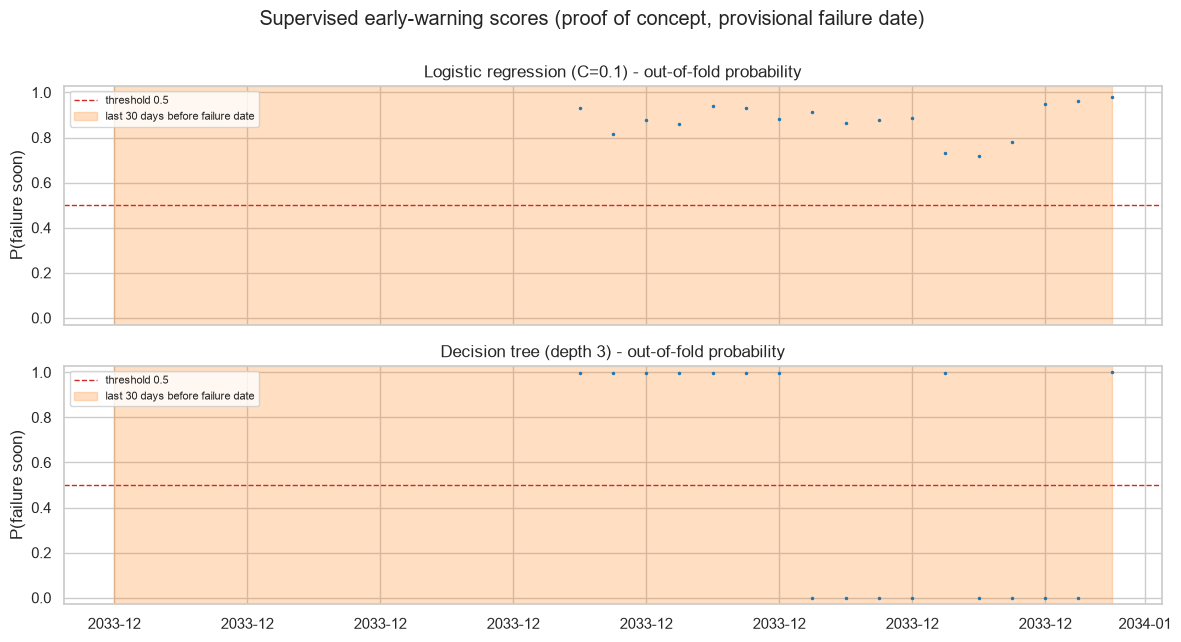

In [11]:
h_start = FAILURE_DATE - pd.Timedelta(days=MAIN_H)
names = [n for n in oof if not n.startswith('Baseline')]
fig, axes = plt.subplots(len(names), 1, figsize=(12, 3.2 * len(names)), sharex=True)
axes = np.atleast_1d(axes)
for ax, n in zip(axes, names):
    p = oof[n]
    ax.plot(p.index, p.values, '.', ms=3, color='tab:blue')
    ax.axhline(THRESHOLD, color='tab:red', ls='--', lw=1, label=f'threshold {THRESHOLD}')
    ax.axvspan(h_start, FAILURE_DATE, color='tab:orange', alpha=0.25, label=f'last {MAIN_H} days before failure date')
    ax.set_ylabel('P(failure soon)')
    ax.set_ylim(-0.03, 1.03)
    ax.set_title(n + ' - out-of-fold probability')
    ax.legend(loc='upper left', fontsize=8)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
fig.suptitle('Supervised early-warning scores (proof of concept, provisional failure date)', y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / 'notebook_05_plot_01.png', dpi=130, bbox_inches='tight')
plt.show()

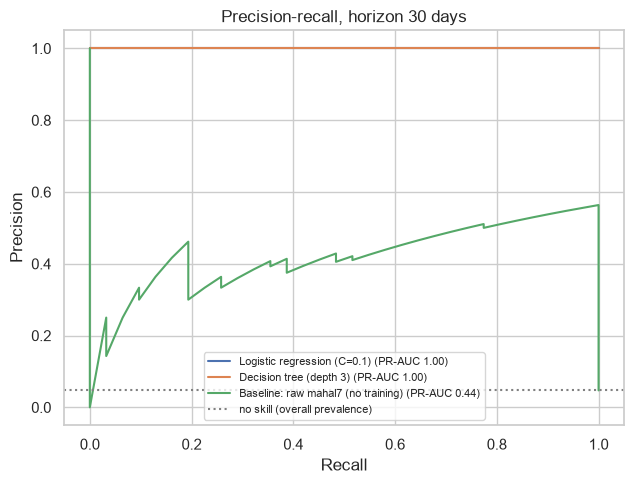

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for n, p in oof.items():
    ok = p.notna().to_numpy()
    prec, rec, _ = precision_recall_curve(y_main[ok], p[ok])
    ax.plot(rec, prec, label=f'{n} (PR-AUC {average_precision_score(y_main[ok], p[ok]):.2f})')
ax.axhline(y_main.mean(), color='gray', ls=':', label='no skill (overall prevalence)')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title(f'Precision-recall, horizon {MAIN_H} days')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / 'notebook_05_plot_02.png', dpi=130, bbox_inches='tight')
plt.show()

## Analysis step 12

Plot model scores through time and compare precision-recall curves. Higher curves indicate better precision at a given recall; the PR-AUC is especially useful when positive labels are rare.

,coef
channel_099_log__mean30,0.657
channel_107__mean30,-0.260
channel_104__mean7,-0.251
channel_104__mean14,-0.240
channel_099_log__mean14,0.232
channel_100__mean30,0.223
channel_108__std14,0.202
channel_094__mean30,-0.202
channel_101__mean14,0.201
channel_099_log__mean7,0.183


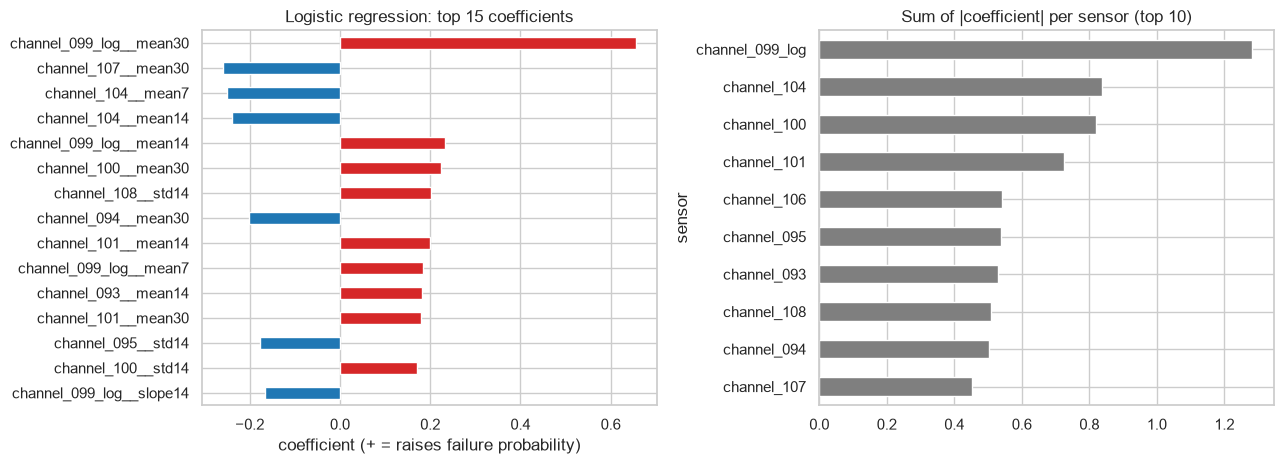

In [13]:
lr_final = make_lr(LR_C).fit(X_all, y_main)
tree_final = make_tree(TREE_DEPTH).fit(X_all, y_main)

coef = pd.Series(lr_final.named_steps['model'].coef_[0], index=FEATURES)
coef_table = pd.DataFrame({'coef': coef, 'abs_coef': coef.abs()})
coef_table['sensor'] = [f.split('__')[0] for f in coef_table.index]
top = coef_table.sort_values('abs_coef', ascending=False).head(15)
display(top[['coef']].round(3))

by_sensor = coef_table.groupby('sensor')['abs_coef'].sum().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
top['coef'][::-1].plot.barh(ax=axes[0], color=np.where(top['coef'][::-1] > 0, 'tab:red', 'tab:blue'))
axes[0].set_title('Logistic regression: top 15 coefficients')
axes[0].set_xlabel('coefficient (+ = raises failure probability)')
by_sensor[::-1].plot.barh(ax=axes[1], color='tab:gray')
axes[1].set_title('Sum of |coefficient| per sensor (top 10)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'notebook_05_plot_03.png', dpi=130, bbox_inches='tight')
plt.show()

In [14]:
print(export_text(tree_final.named_steps['model'], feature_names=FEATURES, max_depth=TREE_DEPTH))
imp = pd.Series(tree_final.named_steps['model'].feature_importances_, index=FEATURES)
display(imp[imp > 0].sort_values(ascending=False).head(10).round(3).to_frame('tree_importance'))

|--- channel_099_log__mean30 <= 11.16
|   |--- class: 0
|--- channel_099_log__mean30 >  11.16
|   |--- channel_093__slope14 <= 0.04
|   |   |--- class: 1
|   |--- channel_093__slope14 >  0.04
|   |   |--- class: 1



,tree_importance
channel_099_log__mean30,1.0
channel_093__slope14,0.0


## Analysis step 13

Fit final models and inspect logistic coefficients and tree rules/importances. These summaries describe which features influenced the fitted models, but do not establish causal effects.

## Analysis step 14

Export the evaluation summaries, event timing, parameter comparisons, and final model bundles for the comparison notebook and future scoring.

In [15]:
summary.to_csv(OUT_DIR / '05_supervised_summary.csv')
timing.to_csv(OUT_DIR / '05_supervised_event_timing.csv')
grid.to_csv(OUT_DIR / '05_supervised_grid.csv', index=False)
horizon_table.to_csv(OUT_DIR / '05_supervised_horizon_sensitivity.csv')
gap_table.to_csv(OUT_DIR / '05_supervised_gap_sensitivity.csv')
coef_table.sort_values('abs_coef', ascending=False).to_csv(OUT_DIR / '05_logreg_coefficients.csv')

# Persist the healthy-baseline covariance behind the mahal7 feature (notebook 04) so
# that score_new() can reproduce all 87 features instead of imputing mahal7. It is fit
# only on the 2032 baseline rows: never on future or evaluation data.
from sklearn.covariance import LedoitWolf

CORE = cfg['core_sensors']
mean7_cols = [f'{c}__mean7' for c in CORE]
base_rows = table['is_baseline'].astype(bool) & table[mean7_cols].notna().all(axis=1)
mahal = LedoitWolf().fit(table.loc[base_rows, mean7_cols].to_numpy(dtype=float))
print('mahal7 covariance: fit on', int(base_rows.sum()), 'baseline rows,',
      len(mean7_cols), 'mean7 columns')

# Persist the preprocessing scaler that notebook 03 fit on the 2032 healthy baseline.
# Without it the standalone score_new() cannot turn raw sensor values into the scaled
# window it was trained on. The scaler is loaded as-is; it is never refit here.
INTERIM_DIR = ROOT / 'data' / 'interim'
scaler_bundle = joblib.load(INTERIM_DIR / 'channel_scaler.joblib')
print('sensor scaler: loaded from', INTERIM_DIR / 'channel_scaler.joblib',
      '| columns:', len(scaler_bundle['columns']),
      '| fit on', scaler_bundle['n_baseline_rows'], 'baseline rows (year',
      scaler_bundle['baseline_year'], ')')

bundle = {'pipeline': lr_final, 'features': FEATURES, 'horizon': MAIN_H,
          'threshold': THRESHOLD, 'sustain_k': SUSTAIN_K,
          'mahal_baseline': {'estimator': mahal, 'mean7_columns': mean7_cols,
                             'n_baseline_rows': int(base_rows.sum())},
          'sensor_scaler': scaler_bundle,
          'note': 'Fit on all usable rows; proof of concept with one provisional failure event.'}
joblib.dump(bundle, MODEL_DIR / '05_logreg_early_warning.joblib')
joblib.dump({**bundle, 'pipeline': tree_final}, MODEL_DIR / '05_tree_early_warning.joblib')
print('saved tables to', OUT_DIR)
print('saved models to', MODEL_DIR)

mahal7 covariance: fit on 364 baseline rows, 14 mean7 columns
sensor scaler: loaded from D:\ML_NTI\Predictive Maintanance\predictive-maintenance\data\interim\channel_scaler.joblib | columns: 100 | fit on 366 baseline rows (year 2032 )


saved tables to D:\ML_NTI\Predictive Maintanance\predictive-maintenance\reports\tables
saved models to D:\ML_NTI\Predictive Maintanance\predictive-maintenance\models


## Analysis step 15

Model artifacts and evaluation tables are saved for notebook 07. Compare results with the label provenance and chronological split in mind, especially when the configured event date is provisional.